In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, cohen_kappa_score,
    matthews_corrcoef, log_loss, confusion_matrix
)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'
print("Gradient Boosting and diagnostic packages successfully loaded.")

Gradient Boosting and diagnostic packages successfully loaded.


In [2]:
csv_path = "womens_clothing_classification_dataset.csv"
if not os.path.exists(csv_path):
    csv_path = os.path.join("27-10-2026", "Task 1", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(csv_path)
print(f"Loaded dataset: {df.shape[0]} rows, {df.shape[1]} columns")

num_features = [
    'Age', 'Rating', 'Positive Feedback Count', 'Review_Length',
    'Review_Word_Count', 'Exclamation_Count', 'Sentiment_Compound',
    'Sentiment_Pos', 'Sentiment_Neg', 'Positive_Word_Count',
    'Negative_Word_Count', 'Fit_Issue_Word_Count', 'Rating_x_Sentiment'
]
cat_features = ['Department Name', 'Division Name']
target = 'Recommended IND'

X = df[num_features + cat_features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.15, random_state=42, stratify=y_train
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_features)
    ]
)

X_tr_trans = preprocessor.fit_transform(X_tr)
X_val_trans = preprocessor.transform(X_val)
X_test_trans = preprocessor.transform(X_test)
X_train_trans = preprocessor.transform(X_train)

cat_cols = list(preprocessor.named_transformers_['cat'].get_feature_names_out(cat_features))
all_feature_names = num_features + cat_cols
print(f"Total features: {len(all_feature_names)}")

Loaded dataset: 23486 rows, 23 columns
Total features: 20


In [3]:
lr_candidates = [0.01, 0.05, 0.1, 0.2]
depth_candidates = [3, 5, 8]
subsample_candidates = [0.6, 0.8, 1.0]

grid_results = []
learning_rate_curves = {}

for lr in lr_candidates:
    for depth in depth_candidates:
        for subsample in subsample_candidates:
            gb = GradientBoostingClassifier(
                n_estimators=300,
                learning_rate=lr,
                max_depth=depth,
                subsample=subsample,
                n_iter_no_change=10,
                tol=1e-4,
                validation_fraction=0.15,
                random_state=42
            )
            t0 = time.time()
            gb.fit(X_train_trans, y_train)
            fit_time = time.time() - t0
            
            y_pred = gb.predict(X_test_trans)
            y_prob = gb.predict_proba(X_test_trans)[:, 1]
            
            grid_results.append({
                'Learning_Rate': lr,
                'Max_Depth': depth,
                'Subsample': subsample,
                'Best_Iteration': gb.n_estimators_,
                'Fit_Time_Seconds': round(fit_time, 2),
                'Test_Accuracy': round(accuracy_score(y_test, y_pred), 4),
                'Test_Recall_Class0': round(recall_score(y_test, y_pred, pos_label=0), 4),
                'Test_Macro_F1': round(f1_score(y_test, y_pred, average='macro'), 4),
                'Test_ROC_AUC': round(roc_auc_score(y_test, y_prob), 4),
                'Test_MCC': round(matthews_corrcoef(y_test, y_pred), 4)
            })
            
    gb_curve = GradientBoostingClassifier(
        n_estimators=300, learning_rate=lr, max_depth=5, subsample=0.8, random_state=42
    )
    gb_curve.fit(X_tr_trans, y_tr)
    val_loss = [log_loss(y_val, p) for p in gb_curve.staged_predict_proba(X_val_trans)]
    train_loss = [log_loss(y_tr, p) for p in gb_curve.staged_predict_proba(X_tr_trans)]
    learning_rate_curves[lr] = {'train': train_loss, 'val': val_loss}

df_grid = pd.DataFrame(grid_results).sort_values(by='Test_Macro_F1', ascending=False)
df_grid.to_csv("gradient_boosting_hyperparameter_tuning_results.csv", index=False)
df_grid.head(10)

,Learning_Rate,Max_Depth,Subsample,Best_Iteration,Fit_Time_Seconds,Test_Accuracy,Test_Recall_Class0,Test_Macro_F1,Test_ROC_AUC,Test_MCC
5,0.01,5,1.0,300,15.24,0.9430,0.8371,0.9022,0.9766,0.8045
19,0.10,3,0.8,68,1.79,0.9425,0.8371,0.9016,0.9770,0.8032
11,0.05,3,1.0,127,3.95,0.9421,0.8419,0.9013,0.9768,0.8027
18,0.10,3,0.6,66,1.51,0.9419,0.8443,0.9012,0.9768,0.8024
4,0.01,5,0.8,300,12.88,0.9423,0.8347,0.9011,0.9759,0.8022
14,0.05,5,1.0,91,4.58,0.9421,0.8371,0.9010,0.9764,0.8019
10,0.05,3,0.8,137,3.61,0.9419,0.8419,0.9010,0.9773,0.8020
1,0.01,3,0.8,300,8.07,0.9421,0.8359,0.9009,0.9762,0.8017
23,0.10,5,1.0,45,2.31,0.9419,0.8407,0.9009,0.9761,0.8019
0,0.01,3,0.6,300,6.78,0.9421,0.8347,0.9008,0.9762,0.8016


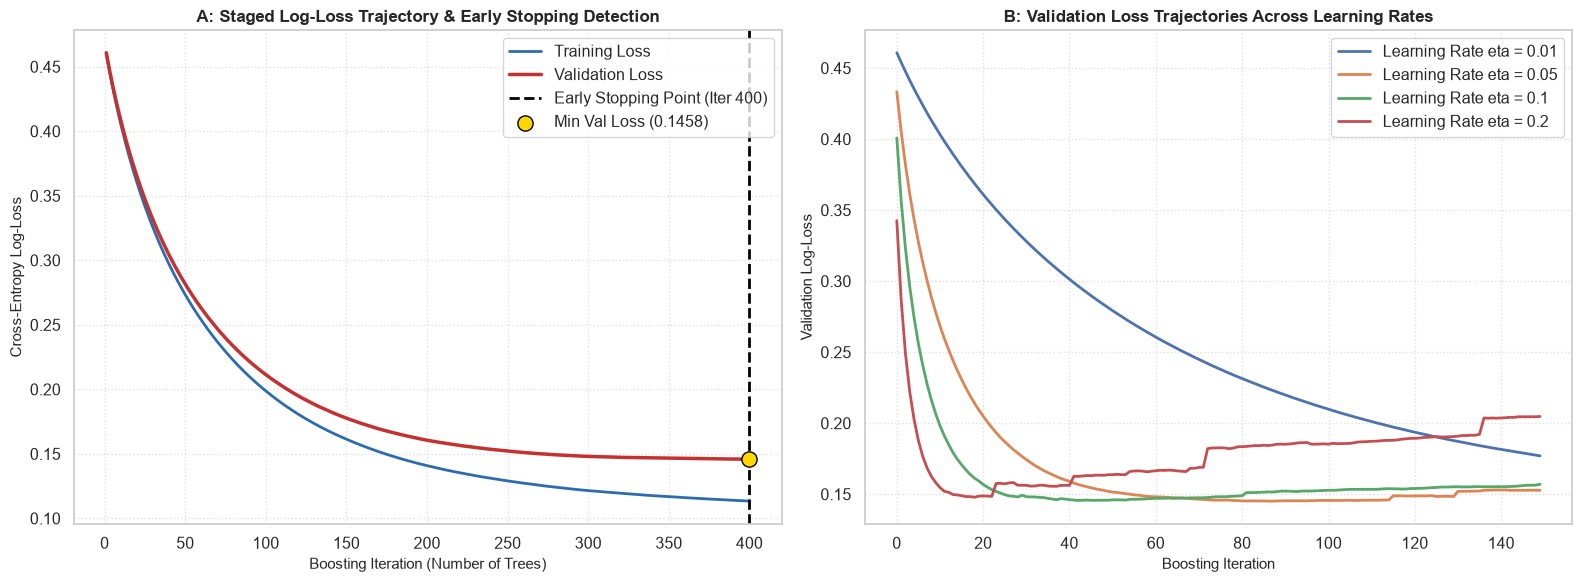

In [4]:
best_params = df_grid.iloc[0]
best_gb = GradientBoostingClassifier(
    n_estimators=400,
    learning_rate=float(best_params['Learning_Rate']),
    max_depth=int(best_params['Max_Depth']),
    subsample=float(best_params['Subsample']),
    n_iter_no_change=15,
    tol=1e-4,
    random_state=42
)
best_gb.fit(X_tr_trans, y_tr)

staged_val_loss = [log_loss(y_val, p) for p in best_gb.staged_predict_proba(X_val_trans)]
staged_tr_loss = [log_loss(y_tr, p) for p in best_gb.staged_predict_proba(X_tr_trans)]
optimal_iter = np.argmin(staged_val_loss) + 1

df_curves = pd.DataFrame({
    'Iteration': np.arange(1, len(staged_tr_loss) + 1),
    'Train_Loss': staged_tr_loss,
    'Validation_Loss': staged_val_loss
})
df_curves.to_csv("early_stopping_learning_curves.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(df_curves['Iteration'], df_curves['Train_Loss'], color='#2B6CB0', linewidth=2, label='Training Loss')
axes[0].plot(df_curves['Iteration'], df_curves['Validation_Loss'], color='#C53030', linewidth=2.5, label='Validation Loss')
axes[0].axvline(optimal_iter, color='black', linestyle='--', linewidth=2, label=f'Early Stopping Point (Iter {optimal_iter})')
axes[0].scatter(optimal_iter, min(staged_val_loss), color='gold', s=120, edgecolors='black', zorder=5, label=f'Min Val Loss ({min(staged_val_loss):.4f})')
axes[0].set_title("A: Staged Log-Loss Trajectory & Early Stopping Detection", fontweight='bold', fontsize=12)
axes[0].set_xlabel("Boosting Iteration (Number of Trees)", fontsize=11)
axes[0].set_ylabel("Cross-Entropy Log-Loss", fontsize=11)
axes[0].legend(loc='upper right', frameon=True)
axes[0].grid(True, linestyle=':', alpha=0.6)

for lr, data in learning_rate_curves.items():
    axes[1].plot(data['val'][:150], label=f'Learning Rate eta = {lr}', linewidth=2)
axes[1].set_title("B: Validation Loss Trajectories Across Learning Rates", fontweight='bold', fontsize=12)
axes[1].set_xlabel("Boosting Iteration", fontsize=11)
axes[1].set_ylabel("Validation Log-Loss", fontsize=11)
axes[1].legend(loc='upper right', frameon=True)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig("early_stopping_training_validation_curves.png", dpi=300)
plt.show()

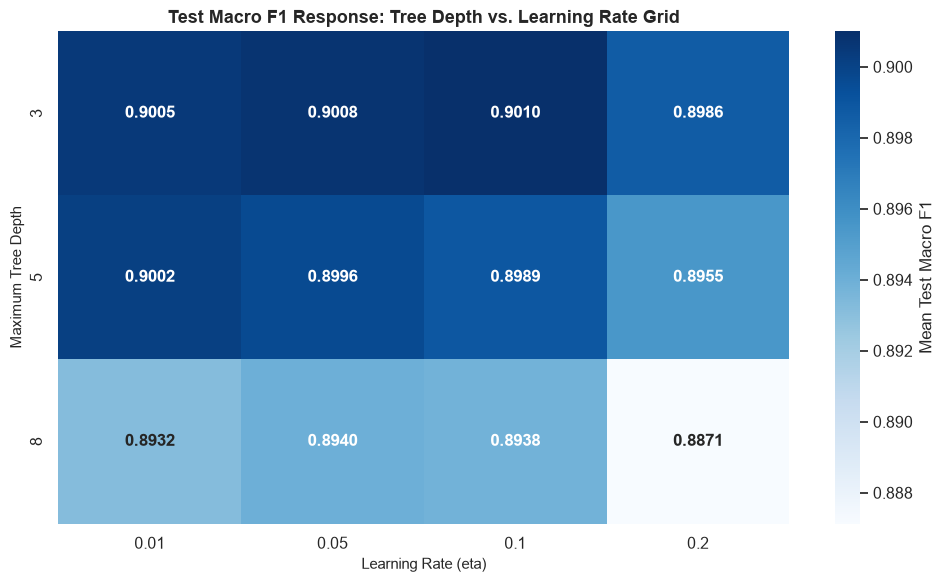

In [5]:
# Heatmap of Hyperparameter Grid Interactions
fig, ax = plt.subplots(figsize=(10, 6))
pivot_f1 = df_grid.pivot_table(index='Max_Depth', columns='Learning_Rate', values='Test_Macro_F1', aggfunc='mean')
sns.heatmap(pivot_f1, annot=True, fmt='.4f', cmap='Blues', cbar_kws={'label': 'Mean Test Macro F1'}, ax=ax, annot_kws={'size': 12, 'weight': 'bold'})
ax.set_title("Test Macro F1 Response: Tree Depth vs. Learning Rate Grid", fontweight='bold', fontsize=13)
ax.set_xlabel("Learning Rate (eta)", fontsize=11)
ax.set_ylabel("Maximum Tree Depth", fontsize=11)
plt.tight_layout()
plt.savefig("learning_rate_depth_subsample_grid.png", dpi=300)
plt.show()

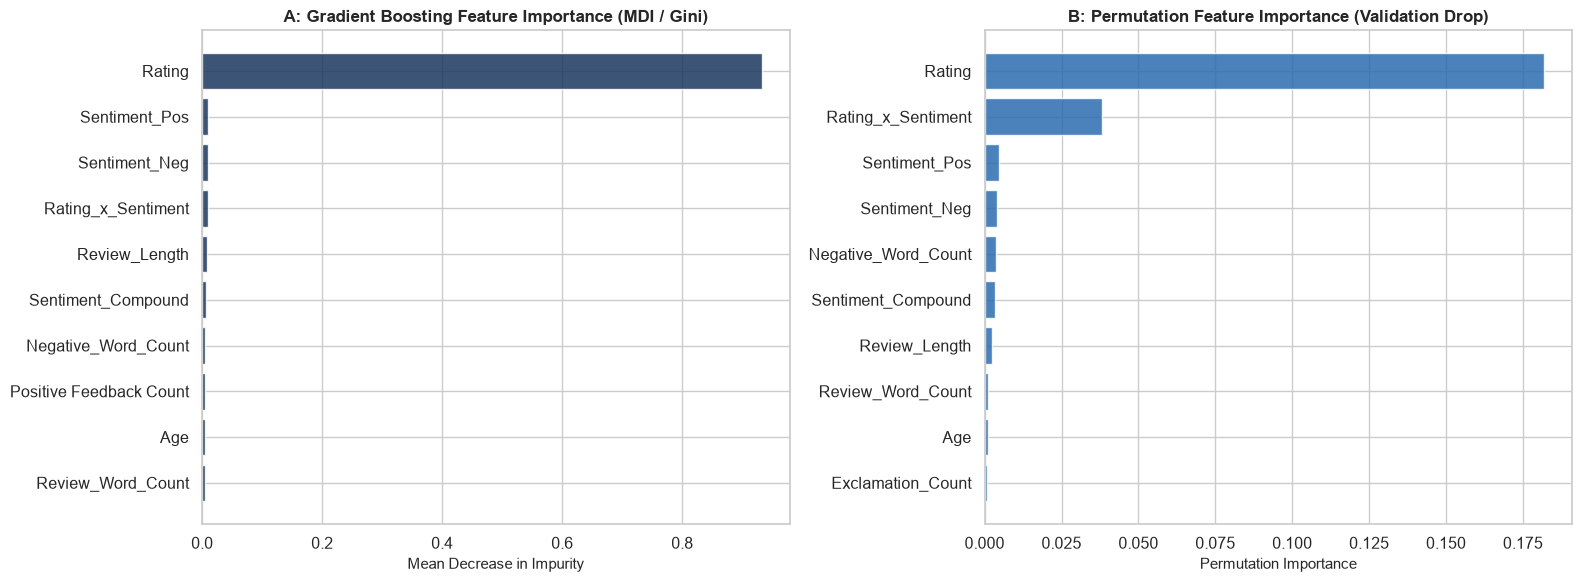

In [6]:
gb_final = GradientBoostingClassifier(
    n_estimators=optimal_iter,
    learning_rate=float(best_params['Learning_Rate']),
    max_depth=int(best_params['Max_Depth']),
    subsample=float(best_params['Subsample']),
    random_state=42
)
gb_final.fit(X_train_trans, y_train)

mdi_importances = gb_final.feature_importances_
perm_importances = permutation_importance(gb_final, X_test_trans, y_test, n_repeats=5, random_state=42, n_jobs=-1).importances_mean

df_feat = pd.DataFrame({
    'Feature': all_feature_names,
    'MDI_Importance': mdi_importances,
    'Permutation_Importance': perm_importances
}).sort_values(by='MDI_Importance', ascending=False)
df_feat.to_csv("gradient_boosting_feature_importance.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
top_mdi = df_feat.sort_values(by='MDI_Importance', ascending=True).tail(10)
axes[0].barh(top_mdi['Feature'], top_mdi['MDI_Importance'], color='#1A365D', alpha=0.85)
axes[0].set_title("A: Gradient Boosting Feature Importance (MDI / Gini)", fontweight='bold', fontsize=12)
axes[0].set_xlabel("Mean Decrease in Impurity", fontsize=11)

top_perm = df_feat.sort_values(by='Permutation_Importance', ascending=True).tail(10)
axes[1].barh(top_perm['Feature'], top_perm['Permutation_Importance'], color='#2B6CB0', alpha=0.85)
axes[1].set_title("B: Permutation Feature Importance (Validation Drop)", fontweight='bold', fontsize=12)
axes[1].set_xlabel("Permutation Importance", fontsize=11)

plt.tight_layout()
plt.savefig("gradient_boosting_feature_importance.png", dpi=300)
plt.show()